Simulation took 0.3640599250793457 seconds
{'grid_building_time': 4.032e-06, 'num_collisions': 46896, 'num_crossings': 9940923, 'total_particles': 10000, 'total_time': 0.355390123, 'trace_time': 0.355386091}


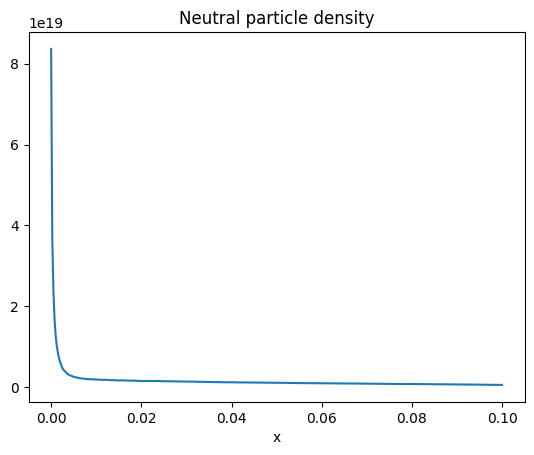

In [ ]:
import numpy as np
from matplotlib import pyplot as plt
import math
import json
import subprocess
import time

config = {}

# Length of the domain
Lx = 0.1
Ly = 0.1
Lz = 0.1

# Number of cells in each direction
nx = 400
ny = 1
nz = 1

# Background parameters
ncells = nx * ny * nz

rate = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    rate[i] = 1.0e7

bgk_stddev = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    bgk_stddev[i] = 1.0e4

bgk_mean_x = np.zeros(ncells, dtype=np.float64)
for i in range(ncells):
    bgk_mean_x[i] = 1.0e4

bgk_mean_y = np.zeros(ncells, dtype=np.float64)
bgk_mean_z = np.zeros(ncells, dtype=np.float64)

# Translate parameters into json format

config["mesh"] = {
    "type": "voxel",
    "Lx": Lx,
    "Ly": Ly,
    "Lz": Lz,
    "nx": nx,
    "ny": ny,
    "nz": nz
}

config["bgk_processes"] = [
    {
        "rate": rate.tolist(),
        "bgk_stddev": bgk_stddev.tolist(),
        "bgk_mean_x": bgk_mean_x.tolist(),
        "bgk_mean_y": bgk_mean_y.tolist(),
        "bgk_mean_z": bgk_mean_z.tolist()
    }
]

config["sources"] = [
    {
        "type": "point",
        "intensity": 5.0e21,
        "pos": [0, 0.05, 0.05],
        "vel_mean": [100, 0, 0],
        "vel_stddev": 10000,
        "n_particles": 10000,
    }
]

config["boundary_conditions"] = [
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
    {
        "type": "partially_specular",
        "absorption_coefficient": 0.95
    },
    {
        "type": "specular"
    },
    {
        "type": "specular"
    },
]

config["max_steps"] = 1000
config["seed"] = 0

# Run the simulation
inputstring = json.dumps(config)

with open("input.json", "w") as f:
    f.write(inputstring)

start_time = time.time()
subprocess.check_output(["neptune-mc"]).decode("utf-8")
end_time = time.time()

print("Simulation took", end_time - start_time, "seconds")

with open("output.json", "r") as f:
    outputstring = f.read()

output = json.loads(outputstring)

stats = output["stats"]
print(stats)

neutral_density = np.array(output["density"])

x = np.linspace(0,Lx,nx)

plt.plot(x, neutral_density)
plt.title("Neutral particle density")
plt.xlabel("x")
plt.show()
